<a href="https://colab.research.google.com/github/nashlypilar-collab/PROYECTO-ENTRE-GRUPAL-/blob/main/Proyecto_1_Dataset_Sueno_Prediccion_Fatiga.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 1 — Dataset del sueño
## Predicción de la fatiga del día siguiente

**Objetivo:** construir y comparar modelos de regresión para estimar `next_day_fatigue_score` a partir de características personales, hábitos y mediciones de la noche de sueño.

**Pregunta de negocio:** ¿Qué tan bien podemos predecir la puntuación de fatiga del día siguiente con la información disponible al despertar?

**Target:** `next_day_fatigue_score` (variable numérica continua).

## 0. Librerías

La mayoría de las librerías son habituales en Colab. SHAP y Optuna se instalarán solo en las secciones donde se usan.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 1. Carga de la base

En Google Colab, ejecuta la celda y selecciona `sleep_debt_screen_time(1).csv`. No depende de una ruta local específica.

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next((name for name in uploaded if name.lower().endswith('.csv')), None)
    if csv_name is None:
        raise ValueError("No se cargó ningún archivo CSV.")
    df = pd.read_csv(csv_name)
except ImportError:
    # Alternativa para ejecutar fuera de Colab: cambia la ruta por la ubicación del CSV.
    csv_name = "sleep_debt_screen_time(1).csv"
    df = pd.read_csv(csv_name)

print(f"Archivo: {csv_name}")
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas")
df.head()

Saving sleep_debt_screen_time.csv to sleep_debt_screen_time (1).csv
Archivo: sleep_debt_screen_time (1).csv
Dimensiones: 8500 filas y 23 columnas


,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,264,21.5,73,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,18,12.6,25,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,62,16.5,48,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,42,18.9,9,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,78,16.3,5,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


## 2. Reconocimiento y calidad de los datos

In [3]:
display(df.head())
print("\nTipos de datos:")
display(df.dtypes.rename("tipo").to_frame())
print("\nResumen de nulos:")
display(df.isna().sum().rename("nulos").to_frame().sort_values("nulos", ascending=False))
print("Filas duplicadas completas:", df.duplicated().sum())
print("\nResumen numérico:")
display(df.describe().T)

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,264,21.5,73,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,18,12.6,25,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,62,16.5,48,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,42,18.9,9,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,78,16.3,5,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild



Tipos de datos:


,tipo
user_id,int64
age,int64
gender,object
chronotype,object
occupation,object
bedtime_hour,float64
screen_time_before_bed_min,int64
primary_app_category,object
screen_brightness_pct,int64
blue_light_filter_on,bool



Resumen de nulos:


,nulos
user_id,0
age,0
gender,0
chronotype,0
occupation,0
bedtime_hour,0
screen_time_before_bed_min,0
primary_app_category,0
screen_brightness_pct,0
blue_light_filter_on,0


Filas duplicadas completas: 0

Resumen numérico:


,count,mean,std,min,25%,50%,75%,max
user_id,8500.0,4250.500000,2453.882977,1.00,2125.75,4250.50,6375.25,8500.00
age,8500.0,28.099647,9.007551,16.00,21.00,27.00,34.00,65.00
bedtime_hour,8500.0,13.883186,10.836579,0.00,1.09,22.20,23.15,24.00
screen_time_before_bed_min,8500.0,53.744118,35.349292,5.00,29.00,45.00,68.00,240.00
screen_brightness_pct,8500.0,68.770235,18.923090,5.00,56.00,69.00,83.00,100.00
caffeine_intake_mg,8500.0,79.650000,78.348824,0.00,22.00,55.50,113.00,500.00
caffeine_last_hour,8500.0,15.905871,3.844196,6.00,13.20,16.00,18.70,23.00
physical_activity_min,8500.0,29.761882,30.000228,0.00,8.00,20.00,42.00,180.00
room_temperature_f,8500.0,70.083506,3.962443,58.00,67.40,70.10,72.70,82.00
ambient_noise_db,8500.0,34.972753,10.011726,10.00,28.20,35.00,41.50,70.00


In [4]:
# Revisión de cardinalidad y categorías en variables de texto
cat_cols_all = df.select_dtypes(include=["object", "bool", "category"]).columns
cardinalidad = pd.DataFrame({
    "valores_unicos": df[cat_cols_all].nunique(dropna=False),
    "ejemplos": [df[c].dropna().unique()[:8].tolist() for c in cat_cols_all]
})
display(cardinalidad)

,valores_unicos,ejemplos
gender,3,"[Female, Male, Non-Binary]"
chronotype,3,"[Intermediate, Night Owl, Early Bird]"
occupation,5,"[Student, Professional, Retired, Unemployed, F..."
primary_app_category,7,"[Social Media, Short-Form Video, Messaging, St..."
blue_light_filter_on,2,"[False, True]"
sleep_debt_category,4,"[Moderate, No Debt, Mild, Severe]"


### Interpretación de calidad

- No eliminaremos valores atípicos automáticamente: primero revisaremos rangos y distribuciones.
- Si hay nulos, se imputarán dentro del pipeline, ajustando la imputación únicamente con los datos de entrenamiento.
- `user_id` se tratará como identificador, no como predictor, porque su valor numérico no tiene significado explicativo conocido.
- `sleep_debt_category` se excluirá de los predictores: es una categoría derivada/relacionada con el sueño y su regla de construcción no está documentada en los archivos entregados. Excluirla reduce el riesgo de fuga de información.

## 3. EDA — variable objetivo

count    8500.000000
mean        4.549893
std         0.954115
min         1.070000
25%         3.890000
50%         4.520000
75%         5.180000
max         8.850000
Name: next_day_fatigue_score, dtype: float64
Nulos en target: 0


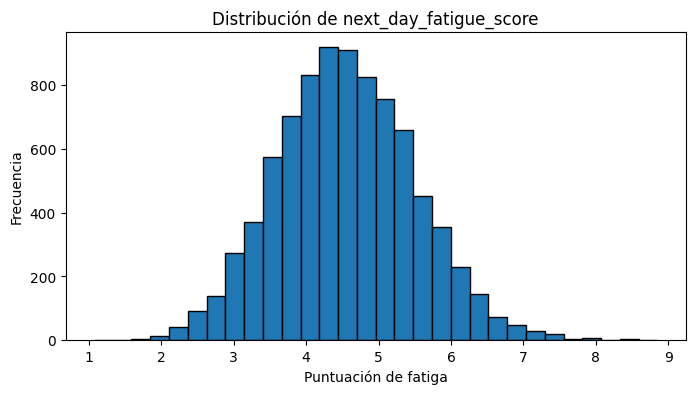

In [5]:
TARGET = "next_day_fatigue_score"
if TARGET not in df.columns:
    raise KeyError(f"No se encontró la variable objetivo {TARGET!r} en el CSV.")

y_eda = pd.to_numeric(df[TARGET], errors="coerce")
print(y_eda.describe())
print("Nulos en target:", y_eda.isna().sum())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_eda.dropna(), bins=30, edgecolor="black")
ax.set_title("Distribución de next_day_fatigue_score")
ax.set_xlabel("Puntuación de fatiga")
ax.set_ylabel("Frecuencia")
plt.show()

## 4. EDA — variables predictoras y relaciones

Las siguientes visualizaciones son descriptivas; no demuestran causalidad.

,correlacion_con_fatiga
total_sleep_hours,-0.688568
sleep_efficiency_pct,-0.536935
rem_sleep_pct,-0.337327
deep_sleep_pct,-0.190759
bedtime_hour,-0.132016
room_temperature_f,0.011141
user_id,0.013405
physical_activity_min,0.016990
ambient_noise_db,0.067587
caffeine_last_hour,0.131273


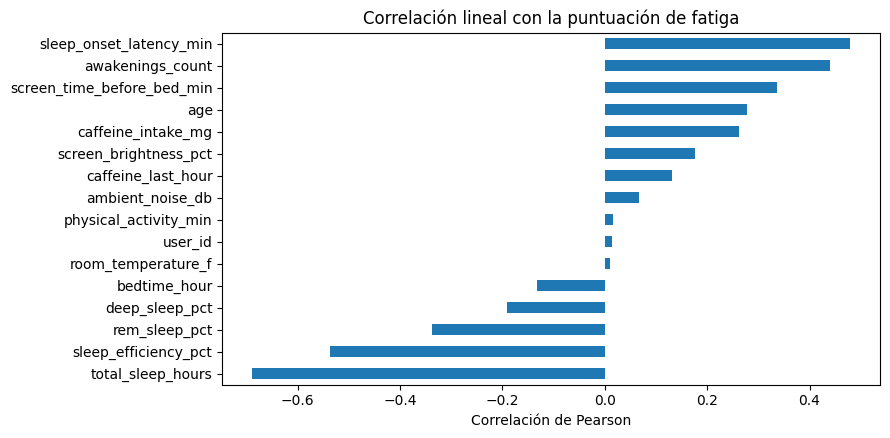

In [6]:
numeric_eda = df.select_dtypes(include=np.number).columns.tolist()
if TARGET in numeric_eda:
    numeric_eda.remove(TARGET)

# Correlaciones numéricas con el target, solo como exploración descriptiva.
correlaciones = df[numeric_eda + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
display(correlaciones.to_frame("correlacion_con_fatiga"))

fig, ax = plt.subplots(figsize=(9, max(4, len(correlaciones) * 0.28)))
correlaciones.plot(kind="barh", ax=ax)
ax.set_title("Correlación lineal con la puntuación de fatiga")
ax.set_xlabel("Correlación de Pearson")
plt.tight_layout()
plt.show()

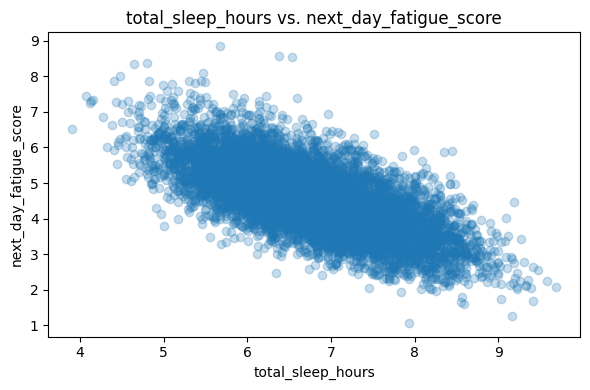

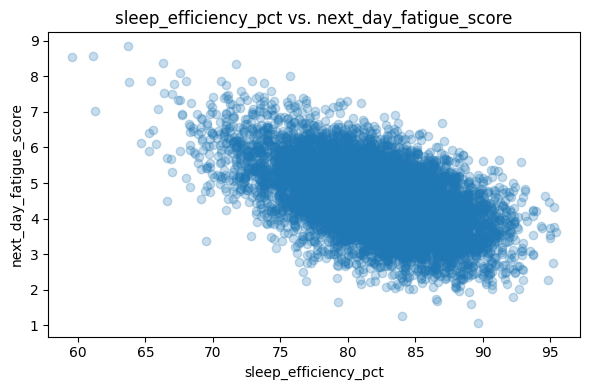

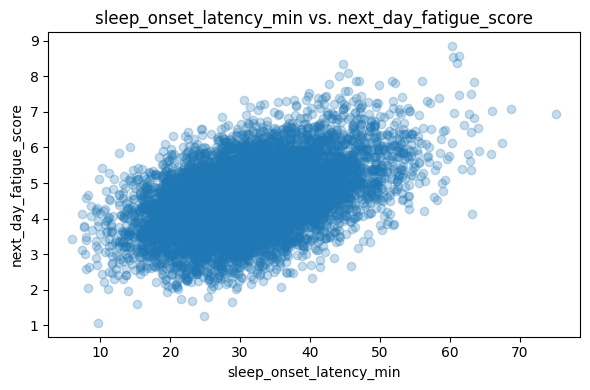

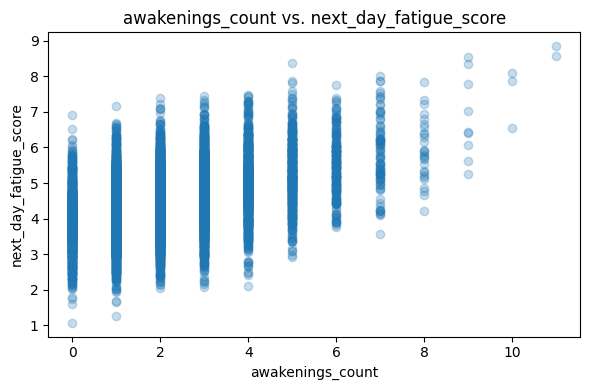

In [7]:
# Diagramas de dispersión para las relaciones numéricas más relevantes según correlación absoluta
top_corr = correlaciones.abs().sort_values(ascending=False).head(4).index.tolist()
for col in top_corr:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(df[col], df[TARGET], alpha=0.25)
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
    ax.set_title(f"{col} vs. {TARGET}")
    plt.tight_layout()
    plt.show()

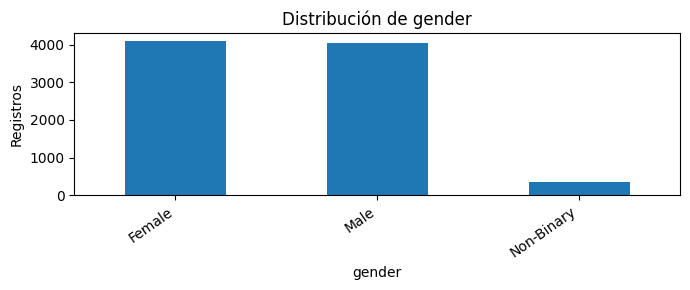

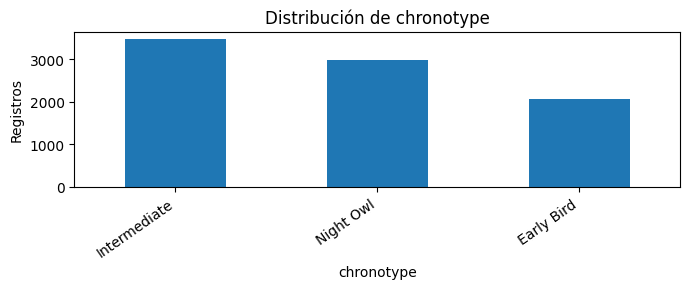

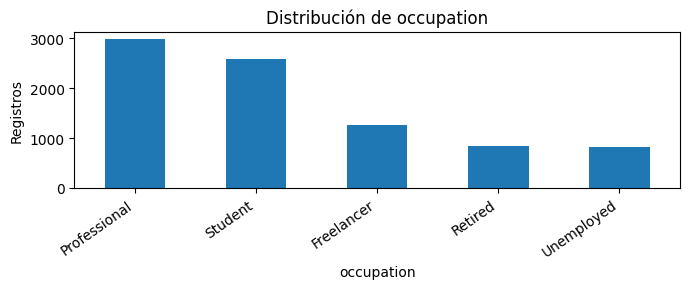

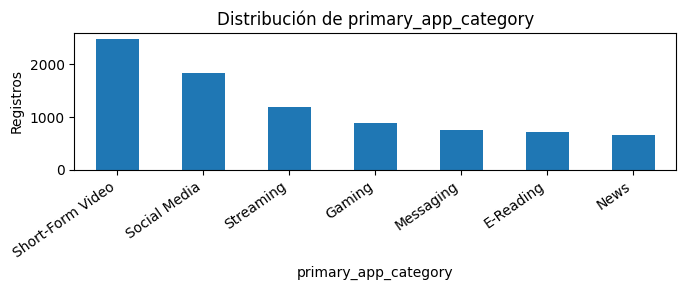

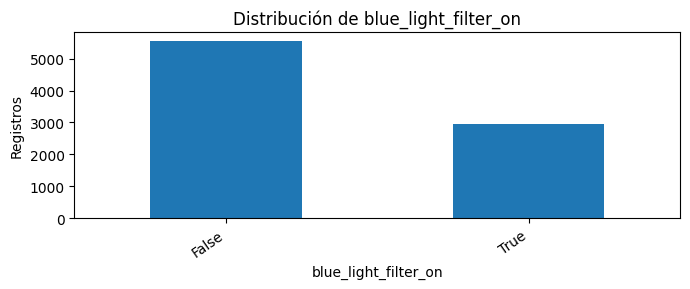

In [8]:
# Distribución de las variables categóricas disponibles
cat_eda = df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()
for col in cat_eda:
    if col == "sleep_debt_category":
        continue  # se excluye del modelo y se muestra solo como descripción de la base
    counts = df[col].value_counts(dropna=False).head(15)
    ax = counts.plot(kind="bar", figsize=(7, 3), title=f"Distribución de {col}")
    ax.set_ylabel("Registros")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### Guía para las conclusiones del EDA

Al ejecutar las celdas, registra en tu informe: (1) forma de la distribución del target, (2) variables numéricas con mayor asociación lineal, (3) diferencias visibles entre categorías, (4) valores extremos que requieran revisión y (5) limitaciones de la base. No se incluyen conclusiones numéricas prefabricadas: deben redactarse a partir de las salidas reales de la ejecución.

## 5. Preparación y selección inicial de variables

Se excluyen `user_id`, `sleep_debt_category` y el target de las predictoras. Para el escenario de predicción al despertar, las mediciones de la noche anterior pueden utilizarse. Si el modelo se necesitara antes de dormir, habría que revisar y excluir las mediciones que todavía no estarían disponibles.

In [9]:
excluded_cols = ["user_id", "sleep_debt_category", TARGET]
X = df.drop(columns=[c for c in excluded_cols if c in df.columns]).copy()
y = pd.to_numeric(df[TARGET], errors="coerce")

# Quitar únicamente filas cuyo target no se pueda usar; no imputamos la respuesta.
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

# Separar columnas según tipo; los booleanos se tratan como categóricos.
cat_cols = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Predictoras numéricas:", num_cols)
print("Predictoras categóricas:", cat_cols)
print("Registros útiles:", len(X))
print("Nulos en X:", int(X.isna().sum().sum()))

Predictoras numéricas: ['age', 'bedtime_hour', 'screen_time_before_bed_min', 'screen_brightness_pct', 'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min', 'room_temperature_f', 'ambient_noise_db', 'sleep_onset_latency_min', 'total_sleep_hours', 'rem_sleep_pct', 'deep_sleep_pct', 'awakenings_count', 'sleep_efficiency_pct']
Predictoras categóricas: ['gender', 'chronotype', 'occupation', 'primary_app_category', 'blue_light_filter_on']
Registros útiles: 8500
Nulos en X: 0


## 6. Separación entrenamiento/prueba y pipeline de preparación

Usamos `train_test_split`, como en la Sesión 6. El conjunto de prueba queda reservado para la evaluación final. `ColumnTransformer` y `Pipeline` son adaptaciones para asegurar que imputación, escalamiento y codificación se ajusten dentro de cada entrenamiento y no filtren información de prueba.

El escalamiento ayuda a la regresión lineal; para los árboles no es necesario, pero puede permanecer en el preprocesamiento común sin afectar su lógica de partición.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (6800, 20) | Prueba: (1700, 20)


## 7. Línea base y modelos iniciales

Entrenaremos una regresión lineal, un árbol de regresión y dos modelos de ensamble. La comparación se hará con MAE, RMSE y R².

In [11]:
models = {
    "Regresión lineal": LinearRegression(),
    "Árbol de regresión": DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=5),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

fitted_models = {}
results = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preparation", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    results.append({
        "Modelo": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

,Modelo,MAE,RMSE,R2
0,Regresión lineal,0.328537,0.406356,0.813355
3,Gradient Boosting,0.339618,0.421136,0.799531
2,Random Forest,0.360217,0.448251,0.772885
1,Árbol de regresión,0.446505,0.560030,0.645493


### Cómo interpretar las métricas

- **MAE:** error absoluto promedio en unidades de la puntuación de fatiga; menor es mejor.
- **RMSE:** penaliza más los errores grandes; menor es mejor.
- **R²:** proporción de variabilidad explicada por el modelo en el conjunto evaluado; puede ser negativo si predice peor que una referencia basada en la media.

Estos resultados son del conjunto de prueba reservado. No elegir un modelo solo por R²: prioriza MAE y revisa también RMSE y la brecha entre validación y prueba.

## 8. Cross validation (validación cruzada)

Comparamos los modelos en los mismos pliegues del conjunto de entrenamiento usando MAE. El test no participa en la selección. Como el archivo no documenta mediciones repetidas por persona ni una secuencia temporal longitudinal, usamos KFold aleatorio; si los datos representan observaciones repetidas o cronológicas, debe cambiarse por una estrategia agrupada o temporal.

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preparation", preprocessor), ("model", estimator)])
    scores = cross_val_score(pipe, X_train, y_train, scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1)
    mae_scores = -scores
    cv_rows.append({
        "Modelo": name,
        "MAE CV promedio": mae_scores.mean(),
        "Desviación MAE CV": mae_scores.std()
    })
cv_df = pd.DataFrame(cv_rows).sort_values("MAE CV promedio")
display(cv_df)

,Modelo,MAE CV promedio,Desviación MAE CV
0,Regresión lineal,0.326322,0.006128
3,Gradient Boosting,0.338995,0.007556
2,Random Forest,0.361700,0.006781
1,Árbol de regresión,0.453592,0.010496


## 9. Paso 1 — Feature importance

Usamos permutation importance sobre el mejor modelo seleccionado por MAE de validación cruzada. La importancia por permutación mide cuánto empeora la métrica cuando se desordena una variable. Se calcula sobre el conjunto de prueba para interpretar el modelo final, pero no se usa para volver a ajustar hiperparámetros. La importancia no implica causalidad.

Modelo con menor MAE medio en CV: Regresión lineal


,variable,importancia_media,desviacion
15,total_sleep_hours,0.424014,0.004416
18,awakenings_count,0.094129,0.004520
6,primary_app_category,0.040725,0.003070
19,sleep_efficiency_pct,0.034709,0.000917
5,screen_time_before_bed_min,0.029727,0.002063
16,rem_sleep_pct,0.021455,0.001606
7,screen_brightness_pct,0.011393,0.000847
8,blue_light_filter_on,0.009264,0.001348
9,caffeine_intake_mg,0.003145,0.001233
10,caffeine_last_hour,0.002697,0.000676


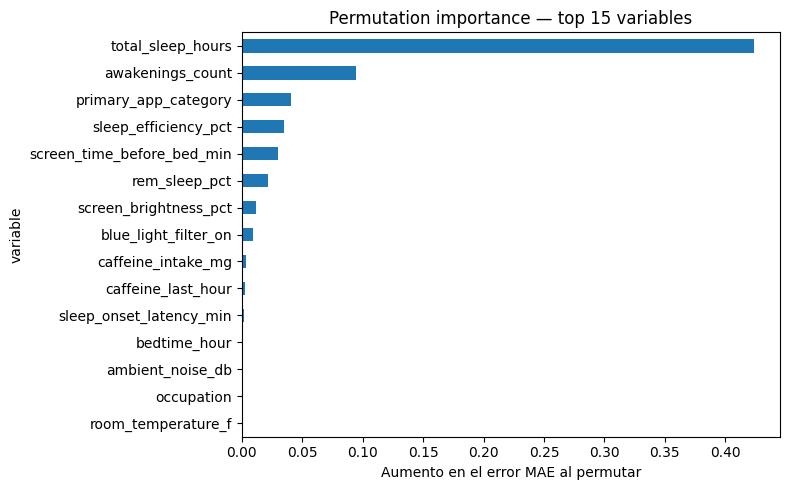

In [13]:
best_cv_name = cv_df.iloc[0]["Modelo"]
best_model = fitted_models[best_cv_name]
print("Modelo con menor MAE medio en CV:", best_cv_name)

perm = permutation_importance(
    best_model, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "variable": X_test.columns,
    "importancia_media": perm.importances_mean,
    "desviacion": perm.importances_std
}).sort_values("importancia_media", ascending=False)
display(importance_df)

plot_df = importance_df.head(15).sort_values("importancia_media")
ax = plot_df.plot(x="variable", y="importancia_media", kind="barh", legend=False, figsize=(8, 5))
ax.set_title("Permutation importance — top 15 variables")
ax.set_xlabel("Aumento en el error MAE al permutar")
plt.tight_layout()
plt.show()

## 10. Paso 2 — SHAP values (interpretabilidad)

SHAP estima la contribución de las variables a las predicciones. Como el pipeline combina transformaciones y modelos, se explica un subconjunto transformado de datos con un `shap.Explainer` genérico. Esta sección es opcional y puede requerir instalar SHAP. La interpretación describe el modelo, no causalidad.

In [14]:
%pip -q install shap

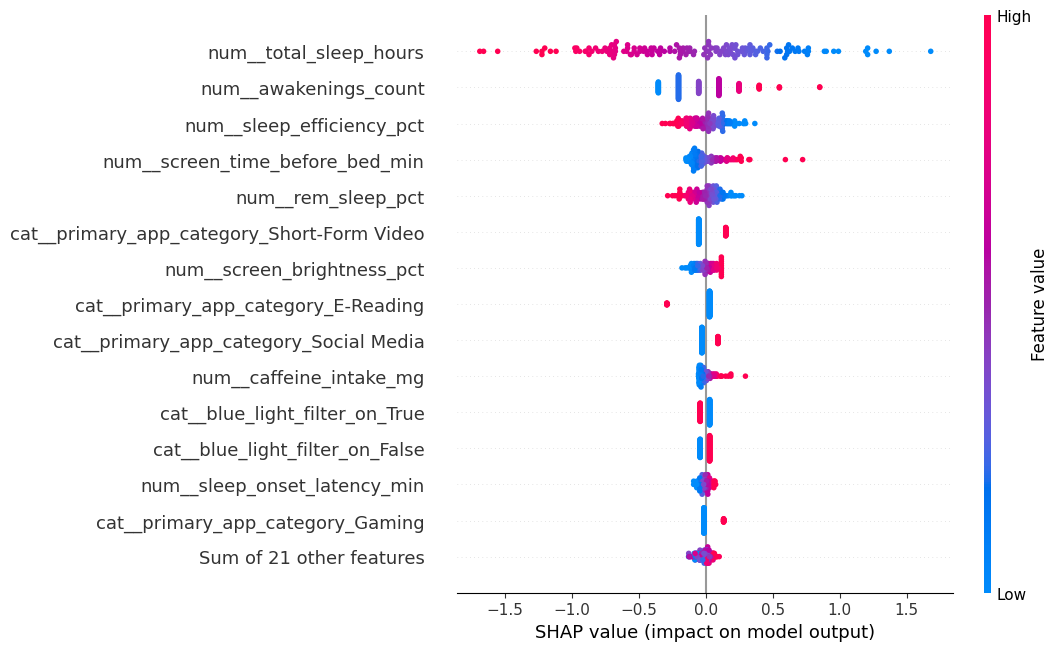

In [15]:

import shap
from scipy import sparse

# 1. Separar el preprocesador y el modelo ya entrenado
preparation = best_model.named_steps["preparation"]
model = best_model.named_steps["model"]

# 2. Seleccionar muestras pequeñas para explicar
X_background = X_train.sample(
    min(100, len(X_train)), random_state=RANDOM_STATE
)
X_explain = X_test.sample(
    min(150, len(X_test)), random_state=RANDOM_STATE
)

# 3. Transformar las variables categóricas y numéricas
# utilizando el preprocesador que ya aprendió del entrenamiento
X_background_transformed = preparation.transform(X_background)
X_explain_transformed = preparation.transform(X_explain)

# 4. Convertir matrices dispersas a matrices numéricas normales
if sparse.issparse(X_background_transformed):
    X_background_transformed = X_background_transformed.toarray()

if sparse.issparse(X_explain_transformed):
    X_explain_transformed = X_explain_transformed.toarray()

# 5. Obtener los nombres de las variables transformadas
feature_names = preparation.get_feature_names_out()

# 6. Crear el explicador SHAP con datos exclusivamente numéricos
explainer = shap.Explainer(
    model.predict,
    X_background_transformed,
    feature_names=feature_names
)

shap_values = explainer(X_explain_transformed)

# 7. Visualizar la importancia e influencia de las variables
shap.plots.beeswarm(shap_values, max_display=15)


Si SHAP falla por incompatibilidad de versión o consumo de recursos, conserva la sección de permutation importance y registra la limitación. No cambies la evaluación del modelo por el hecho de que SHAP no se ejecute.

## 11. Paso 3 — Revisión de Data Leakage

Esta lista combina comprobaciones de código con decisiones que dependen de conocer cómo se recolectaron los datos.

In [16]:
print("Columnas usadas como predictoras:")
print(X.columns.tolist())
print("\nColumnas excluidas explícitamente:", [c for c in excluded_cols if c in df.columns])
print("¿El target está en X?", TARGET in X.columns)
print("¿user_id está en X?", "user_id" in X.columns)
print("¿sleep_debt_category está en X?", "sleep_debt_category" in X.columns)

# Correlación muy alta puede ser una señal para investigar, no prueba automática de leakage.
if TARGET in df.select_dtypes(include=np.number).columns:
    corr_target = df.select_dtypes(include=np.number).corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False)
    display(corr_target.head(10).to_frame("correlacion_absoluta"))

Columnas usadas como predictoras:
['age', 'gender', 'chronotype', 'occupation', 'bedtime_hour', 'screen_time_before_bed_min', 'primary_app_category', 'screen_brightness_pct', 'blue_light_filter_on', 'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min', 'room_temperature_f', 'ambient_noise_db', 'sleep_onset_latency_min', 'total_sleep_hours', 'rem_sleep_pct', 'deep_sleep_pct', 'awakenings_count', 'sleep_efficiency_pct']

Columnas excluidas explícitamente: ['user_id', 'sleep_debt_category', 'next_day_fatigue_score']
¿El target está en X? False
¿user_id está en X? False
¿sleep_debt_category está en X? False


,correlacion_absoluta
total_sleep_hours,0.688568
sleep_efficiency_pct,0.536935
sleep_onset_latency_min,0.479315
awakenings_count,0.440525
rem_sleep_pct,0.337327
screen_time_before_bed_min,0.336067
age,0.278334
caffeine_intake_mg,0.261541
deep_sleep_pct,0.190759
screen_brightness_pct,0.176128


**Comprobaciones de negocio pendientes:**

1. Confirmar cuándo se mide `next_day_fatigue_score` y cuándo se registran las variables de sueño.
2. Confirmar si alguna variable fue calculada directa o indirectamente usando la puntuación de fatiga.
3. Confirmar si `user_id` representa usuarios repetidos; si cada usuario aparece varias veces, la división debería agruparse por usuario para evitar que la misma persona aparezca en entrenamiento y prueba.
4. Confirmar la definición de `sleep_debt_category`; por ahora se excluye porque su regla de construcción no está documentada.

## 12. Paso 4 — Oversampling

**No aplica a este problema de regresión tal como está definido.** Oversampling tradicional como SMOTE se utiliza para clases minoritarias en clasificación, no para un target continuo. No discretizaremos la fatiga solo para forzar esta técnica. Si se planteara después una tarea de clasificación, se evaluaría el desbalance y se aplicaría cualquier remuestreo solo dentro de los pliegues de entrenamiento.

## 13. Paso 5 — Validación cruzada

La comparación de validación cruzada está implementada en la sección 8 y usa exclusivamente `X_train` e `y_train`. El conjunto de prueba se mantiene reservado. Si hay usuarios repetidos, se debe adaptar a `GroupKFold`/`GroupShuffleSplit`; si cada fila corresponde a una fecha en una serie temporal, se debe usar una partición temporal.

## 14. Paso 6 — Modelo de árbol de regresión

Entrenamos un árbol interpretable y mostramos su estructura con profundidad limitada. La visualización usa nombres de variables después de codificar categorías.

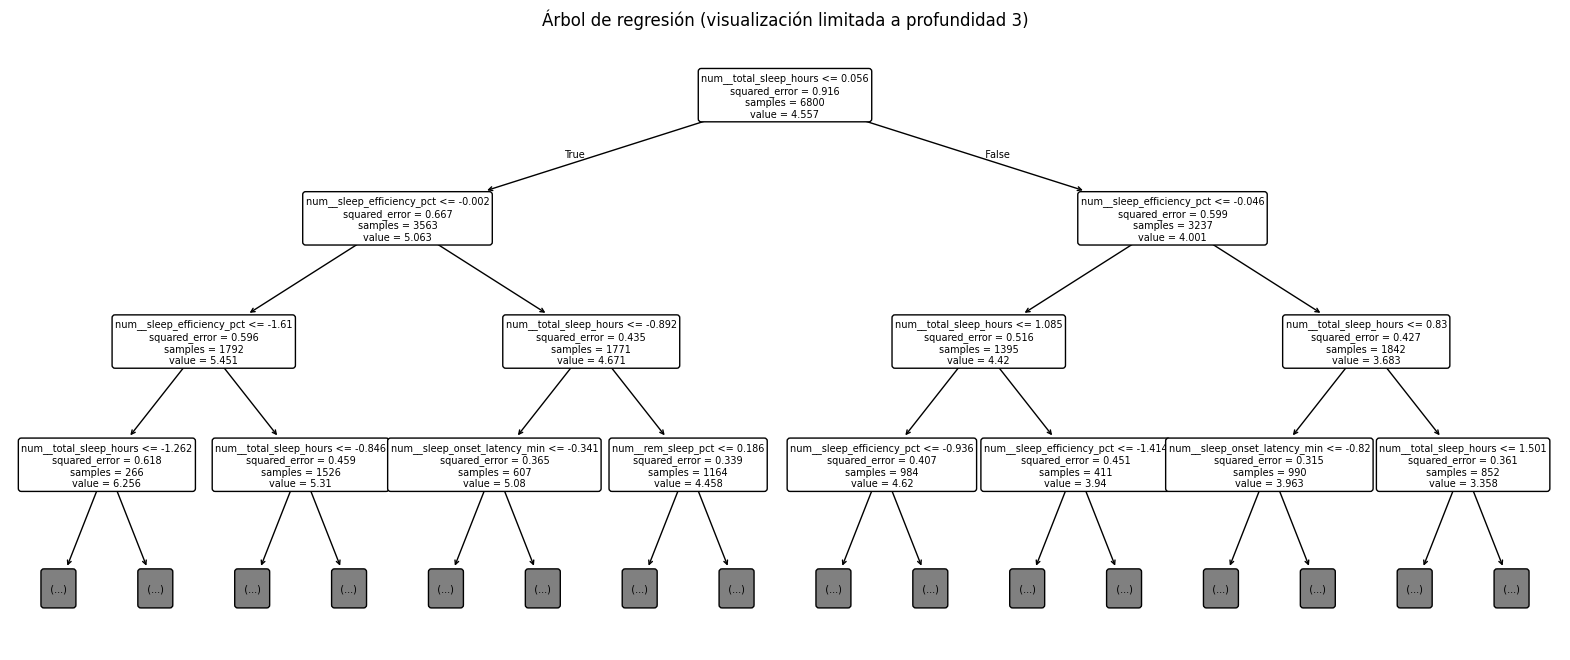

In [17]:
tree_pipe = fitted_models["Árbol de regresión"]
prep_fitted = tree_pipe.named_steps["preparation"]
tree_fitted = tree_pipe.named_steps["model"]
feature_names = prep_fitted.get_feature_names_out()

plt.figure(figsize=(20, 8))
plot_tree(tree_fitted, feature_names=feature_names, filled=False, rounded=True, max_depth=3, fontsize=7)
plt.title("Árbol de regresión (visualización limitada a profundidad 3)")
plt.show()

## 15. Paso 7 — Optuna para ajustar hiperparámetros

Optuna es una librería adicional. Se optimiza MAE mediante validación cruzada solo en el conjunto de entrenamiento. El conjunto de prueba no se consulta en la función objetivo.

In [18]:
%pip -q install optuna

In [19]:
import optuna
from sklearn.model_selection import cross_val_score

def objective(trial):
    model_name = trial.suggest_categorical("modelo", ["DecisionTree", "RandomForest", "GradientBoosting"])
    if model_name == "DecisionTree":
        estimator = DecisionTreeRegressor(
            max_depth=trial.suggest_int("max_depth", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
            random_state=RANDOM_STATE
        )
    elif model_name == "RandomForest":
        estimator = RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=100),
            max_depth=trial.suggest_int("max_depth", 3, 25),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            random_state=RANDOM_STATE, n_jobs=-1
        )
    else:
        estimator = GradientBoostingRegressor(
            n_estimators=trial.suggest_int("n_estimators", 50, 250, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 5),
            random_state=RANDOM_STATE
        )
    pipe = Pipeline(steps=[("preparation", preprocessor), ("model", estimator)])
    scores = cross_val_score(pipe, X_train, y_train, scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1)
    return -scores.mean()

study = optuna.create_study(direction="minimize", study_name="fatigue_regression_mae")
study.optimize(objective, n_trials=20, show_progress_bar=True)
print("Mejor MAE CV:", study.best_value)
print("Mejores hiperparámetros:", study.best_params)

[I 2026-11-06 00:26:40,634] A new study created in memory with name: fatigue_regression_mae


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-11-06 00:27:20,901] Trial 0 finished with value: 0.3874317992144064 and parameters: {'modelo': 'RandomForest', 'n_estimators': 200, 'max_depth': 6, 'min_samples_leaf': 8}. Best is trial 0 with value: 0.3874317992144064.
[I 2026-11-06 00:27:43,690] Trial 1 finished with value: 0.34553238599072006 and parameters: {'modelo': 'GradientBoosting', 'n_estimators': 200, 'learning_rate': 0.023928672558590436, 'max_depth': 4}. Best is trial 1 with value: 0.34553238599072006.
[I 2026-11-06 00:27:50,098] Trial 2 finished with value: 0.3689855569566943 and parameters: {'modelo': 'GradientBoosting', 'n_estimators': 100, 'learning_rate': 0.053052474855926755, 'max_depth': 2}. Best is trial 1 with value: 0.34553238599072006.
[I 2026-11-06 00:27:50,512] Trial 3 finished with value: 0.4247523198789235 and parameters: {'modelo': 'DecisionTree', 'max_depth': 8, 'min_samples_leaf': 11}. Best is trial 1 with value: 0.34553238599072006.
[I 2026-11-06 00:27:57,352] Trial 4 finished with value: 0.35699

### Entrenar el mejor modelo de Optuna y evaluarlo una sola vez en prueba

In [20]:

# Recuperar los mejores parámetros encontrados por Optuna
best_params = study.best_params

print("Modelo seleccionado:", best_params["modelo"])
print("Mejores parámetros:", best_params)

# Crear el modelo con los parámetros correctos
if best_params["modelo"] == "DecisionTree":
    tuned_estimator = DecisionTreeRegressor(
        max_depth=best_params["max_depth"],
        min_samples_leaf=best_params["min_samples_leaf"],
        random_state=RANDOM_STATE
    )

elif best_params["modelo"] == "RandomForest":
    tuned_estimator = RandomForestRegressor(
        n_estimators=best_params["n_estimators"],
        max_depth=best_params["max_depth"],
        min_samples_leaf=best_params["min_samples_leaf"],
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

else:
    tuned_estimator = GradientBoostingRegressor(
        n_estimators=best_params["n_estimators"],
        learning_rate=best_params["learning_rate"],
        max_depth=best_params["max_depth"],
        random_state=RANDOM_STATE
    )

# Crear el pipeline y entrenarlo con los datos de entrenamiento
tuned_model = Pipeline(steps=[
    ("preparation", preprocessor),
    ("model", tuned_estimator)
])

tuned_model.fit(X_train, y_train)

# Evaluar con el conjunto de prueba
tuned_pred = tuned_model.predict(X_test)

tuned_metrics = {
    "Modelo": "Optuna: " + best_params["modelo"],
    "MAE": mean_absolute_error(y_test, tuned_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, tuned_pred)),
    "R2": r2_score(y_test, tuned_pred)
}

print("\nResultados del mejor modelo:")
print(tuned_metrics)


Modelo seleccionado: GradientBoosting
Mejores parámetros: {'modelo': 'GradientBoosting', 'n_estimators': 250, 'learning_rate': 0.14630761267928322, 'max_depth': 2}

Resultados del mejor modelo:
{'Modelo': 'Optuna: GradientBoosting', 'MAE': 0.3338025164107388, 'RMSE': np.float64(0.41393835957064345), 'R2': 0.8063248463700117}


## 16. Paso 8 — Comparación final de modelos

La tabla combina los modelos iniciales evaluados en el mismo test con el modelo ajustado por Optuna. El test se usa aquí para la comparación final, no para seleccionar hiperparámetros.

In [21]:
final_results = results_df.copy()
final_results = pd.concat([final_results, pd.DataFrame([tuned_metrics])], ignore_index=True)
final_results = final_results.sort_values("MAE").reset_index(drop=True)
display(final_results)

best_final = final_results.iloc[0]
print(f"Modelo con menor MAE en prueba: {best_final['Modelo']}")
print(f"MAE en prueba: {best_final['MAE']:.4f}")
print(f"RMSE en prueba: {best_final['RMSE']:.4f}")
print(f"R² en prueba: {best_final['R2']:.4f}")

,Modelo,MAE,RMSE,R2
0,Regresión lineal,0.328537,0.406356,0.813355
1,Optuna: GradientBoosting,0.333803,0.413938,0.806325
2,Gradient Boosting,0.339618,0.421136,0.799531
3,Random Forest,0.360217,0.448251,0.772885
4,Árbol de regresión,0.446505,0.560030,0.645493


Modelo con menor MAE en prueba: Regresión lineal
MAE en prueba: 0.3285
RMSE en prueba: 0.4064
R² en prueba: 0.8134


## 17. Gráfico de valores reales vs. predichos

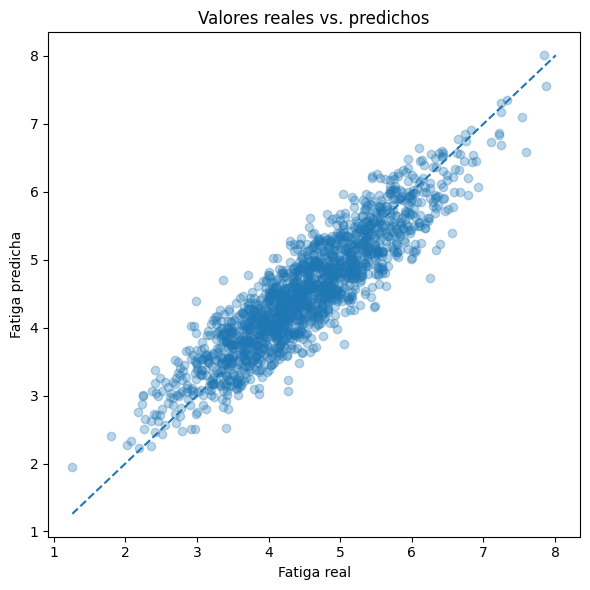

In [22]:
# Usar el modelo con menor MAE de la tabla final para visualizar el ajuste
final_name = best_final["Modelo"]
if final_name.startswith("Optuna:"):
    final_model = tuned_model
else:
    final_model = fitted_models[final_name]
final_pred = final_model.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, final_pred, alpha=0.3)
lims = [min(y_test.min(), final_pred.min()), max(y_test.max(), final_pred.max())]
ax.plot(lims, lims, linestyle="--")
ax.set_xlabel("Fatiga real")
ax.set_ylabel("Fatiga predicha")
ax.set_title("Valores reales vs. predichos")
plt.tight_layout()
plt.show()

## 18. Conclusiones finales — completar tras ejecutar

Responde con los resultados reales obtenidos:

1. ¿Cuál modelo tuvo el menor MAE en el conjunto de prueba?
2. ¿Qué significa ese MAE en unidades de la escala de fatiga?
3. ¿Qué variables tuvieron mayor importancia por permutación? ¿Coincide la interpretación SHAP?
4. ¿La validación cruzada fue estable o mostró alta variabilidad?
5. ¿El modelo parece generalizar bien? Compara validación cruzada y prueba.
6. ¿Qué riesgos de Data Leakage quedaron pendientes de confirmar con conocimiento del negocio?
7. ¿Qué limitaciones tiene la base y qué mejoras propondrías?

**Limitaciones conocidas:** la base no documenta en este proyecto cómo se recolectó cada variable ni la definición exacta de la escala de fatiga. Las asociaciones aprendidas no prueban causalidad. No se utiliza oversampling porque el objetivo es continuo. La sección SHAP/Optuna puede requerir instalar librerías y tiempo de ejecución adicional.